In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(classification_report,accuracy_score,confusion_matrix,ConfusionMatrixDisplay,)
from ucimlrepo import fetch_ucirepo

In [10]:
# Cell 2: Load the dataset
dataset = fetch_ucirepo(id=327)
X = dataset.data.features
y = dataset.data.targets

print(f"Dataset shape: {X.shape}")
print(f"Features: {list(X.columns)}")
print(f"\nFirst 5 rows:")
print(X.head())

Dataset shape: (11055, 30)
Features: ['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']

First 5 rows:
   having_ip_address  url_length  shortining_service  having_at_symbol  \
0                 -1           1                   1                 1   
1                  1           1                   1                 1   
2                  1           0                   1                 1   
3                  1           0                   1                 1   
4                  1           0                  -1                

In [11]:
# Explore the data
print(f"Dataset info:")
print(f"Total samples: {len(X)}")
print(f"Number of features: {X.shape[1]}")
print(f"\nTarget distribution:")
print(y.value_counts())

Dataset info:
Total samples: 11055
Number of features: 30

Target distribution:
result
 1        6157
-1        4898
Name: count, dtype: int64


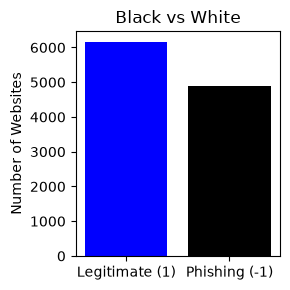

In [5]:
# Visualize class distribution
target_counts = y.value_counts()
plt.figure(figsize=(3, 3))
plt.bar(
    ["Legitimate (1)", "Phishing (-1)"],
    [target_counts.get(1, 0), target_counts.get(-1, 0)],
    color=["blue", "black"],
)
plt.title("Black vs White")
plt.ylabel("Number of Websites")
plt.tight_layout()
plt.show()

In [6]:
# Prepare data for training
y_binary = y.replace({-1: 0, 1: 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Training set size: 8844
Test set size: 2211


In [7]:
# Train the Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train.values.ravel())

y_pred = model.predict(X_test)

In [8]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred,digits=4, target_names=["Phishing", "Legitimate"]))

Model Accuracy: 0.9670

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9722    0.9508    0.9614       956
  Legitimate     0.9632    0.9793    0.9712      1255

    accuracy                         0.9670      2211
   macro avg     0.9677    0.9651    0.9663      2211
weighted avg     0.9671    0.9670    0.9669      2211



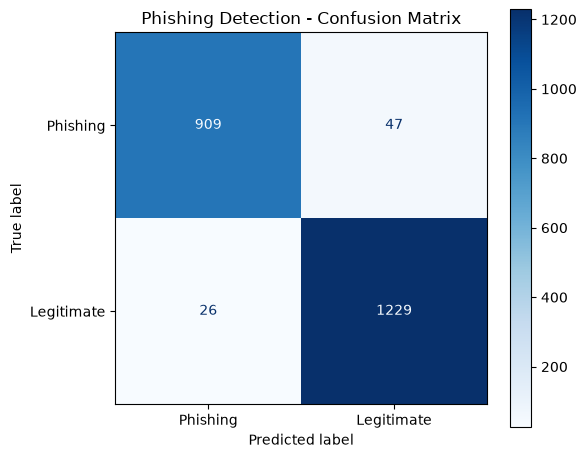

In [13]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Phishing", "Legitimate"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues")
plt.title("Phishing Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

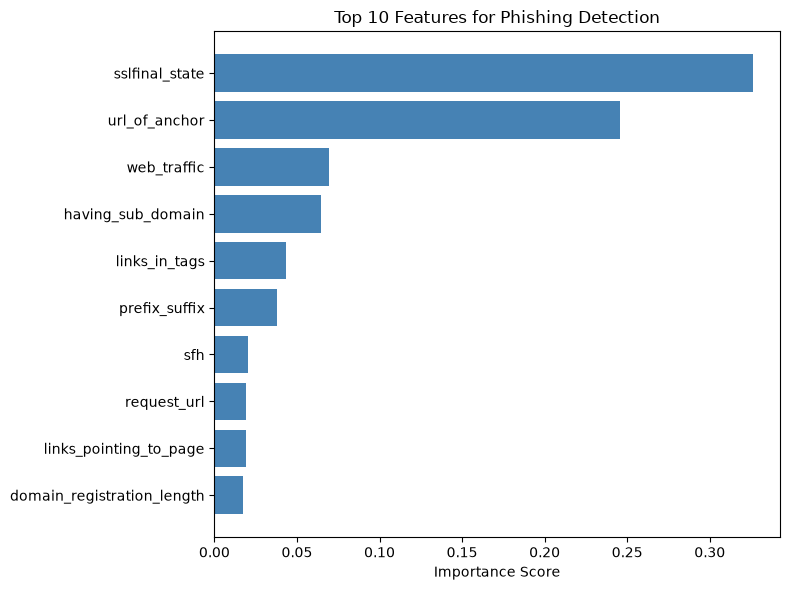


Top 5 most important features:
  sslfinal_state: 0.3262
  url_of_anchor: 0.2455
  web_traffic: 0.0697
  having_sub_domain: 0.0645
  links_in_tags: 0.0433


In [14]:
# Feature importance
importances = model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=True)

top_10 = feature_importance_df.tail(10)

plt.figure(figsize=(8, 6))
plt.barh(top_10["feature"], top_10["importance"], color="steelblue")
plt.xlabel("Importance Score")
plt.title("Top 10 Features for Phishing Detection")
plt.tight_layout()
plt.show()

print("\nTop 5 most important features:")
for _, row in feature_importance_df.tail(5).iloc[::-1].iterrows():
    print(f"  {row['feature']}: {row['importance']:.4f}")

In [15]:
type(model)

sklearn.ensemble._forest.RandomForestClassifier

In [16]:
# Prediction function
def predict_phishing(features_dict):
    """
    Predict whether a website is phishing based on its features.

    Args:
        features_dict: Dictionary with feature names as keys and values (-1, 0, or 1)

    Returns:
        Dictionary with classification and confidence score
    """
    input_df = pd.DataFrame([features_dict])

    for col in X.columns:
        if col not in input_df.columns:
            input_df[col] = 0

    input_df = input_df[X.columns]

    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    phishing_prob = probabilities[0] * 100
    legitimate_prob = probabilities[1] * 100

    label = "LEGITIMATE" if prediction == 1 else "PHISHING"

    return {
        "classification": label,
        "confidence": max(phishing_prob, legitimate_prob),
        "phishing_risk": phishing_prob,
    }

In [17]:
# Test cases
print("=" * 50)
print("PHISHING WEBSITE DETECTOR")
print("=" * 50)

suspicious_site = {
    "having_ip_address": -1,
    "url_length": -1,
    "shortining_service": -1,
    "having_at_symbol": -1,
    "double_slash_redirecting": -1,
    "prefix_suffix": -1,
    "having_sub_domain": -1,
    "sslfinal_state": -1,
    "domain_registration_length": -1,
    "favicon": -1,
}

result = predict_phishing(suspicious_site)
print(f"\nTest 1 - Highly suspicious site:")
print(f"  Classification: {result['classification']}")
print(f"  Confidence: {result['confidence']:.1f}%")
print(f"  Phishing Risk: {result['phishing_risk']:.1f}%")

legitimate_site = {
    "having_ip_address": 1,
    "url_length": 1,
    "shortining_service": 1,
    "having_at_symbol": 1,
    "double_slash_redirecting": 1,
    "prefix_suffix": 1,
    "having_sub_domain": 1,
    "sslfinal_state": 1,
    "domain_registration_length": 1,
    "favicon": 1,
}

result = predict_phishing(legitimate_site)
print(f"\nTest 2 - Clearly legitimate site:")
print(f"  Classification: {result['classification']}")
print(f"  Confidence: {result['confidence']:.1f}%")
print(f"  Phishing Risk: {result['phishing_risk']:.1f}%")

ambiguous_site = {
    "having_ip_address": 1,
    "url_length": -1,
    "shortining_service": 1,
    "having_at_symbol": 1,
    "double_slash_redirecting": 1,
    "prefix_suffix": -1,
    "having_sub_domain": 0,
    "sslfinal_state": 1,
    "domain_registration_length": -1,
    "favicon": 1,
}

result = predict_phishing(ambiguous_site)
print(f"\nTest 3 - Ambiguous site (mixed signals):")
print(f"  Classification: {result['classification']}")
print(f"  Confidence: {result['confidence']:.1f}%")
print(f"  Phishing Risk: {result['phishing_risk']:.1f}%")

PHISHING WEBSITE DETECTOR

Test 1 - Highly suspicious site:
  Classification: PHISHING
  Confidence: 74.0%
  Phishing Risk: 74.0%

Test 2 - Clearly legitimate site:
  Classification: LEGITIMATE
  Confidence: 74.0%
  Phishing Risk: 26.0%

Test 3 - Ambiguous site (mixed signals):
  Classification: LEGITIMATE
  Confidence: 63.0%
  Phishing Risk: 37.0%
